In [1]:

from pathlib import Path
from collections import Counter
import csv
import random
import numpy as np
import torch
import torchvision

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Project paths
DATA_DIR = Path.cwd()
SPLIT_FILE = DATA_DIR / "dataset_split.csv"

RESULTS_DIR = DATA_DIR / "results" / "resnet50"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

# 3. Device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# 4. Verify original dataset split
assert SPLIT_FILE.exists(), (
    f"Missing dataset_split.csv in {DATA_DIR}"
)

with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

train_records = [
    r for r in split_records if r["split"] == "train"
]
val_records = [
    r for r in split_records if r["split"] == "validation"
]
test_records = [
    r for r in split_records if r["split"] == "test"
]

assert len(train_records) == 1402
assert len(val_records) == 280
assert len(test_records) == 279

# 5. Check group separation
train_groups = {r["group"] for r in train_records}
val_groups = {r["group"] for r in val_records}
test_groups = {r["group"] for r in test_records}

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# 6. Summary
print("RESNET-50 EXPERIMENT SETUP")
print("=" * 50)
print("Project:", DATA_DIR)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
print("Seed:", SEED)

print("\nDATASET")
print("Training:", len(train_records))
print("Validation:", len(val_records))
print("Test:", len(test_records))

print("\nTRAINING CLASS DISTRIBUTION")
for label, count in sorted(
    Counter(r["label"] for r in train_records).items()
):
    print(f"{label}: {count}")

print("\nGroup separation: PASSED")
print("Using original, unaugmented split")


RESNET-50 EXPERIMENT SETUP
Project: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database
PyTorch: 2.15.0
Torchvision: 0.29.2
Device: mps
Seed: 42

DATASET
Training: 1402
Validation: 280
Test: 279

TRAINING CLASS DISTRIBUTION
Brittle: 589
Ductile: 711
Mixed: 102

Group separation: PASSED
Using original, unaugmented split


In [2]:

import torch.nn as nn
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# =====================================================
# 1. CLASS MAPPING
# =====================================================

CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

# =====================================================
# 2. IMAGE PREPROCESSING
# =====================================================

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# =====================================================
# 3. SEM DATASET CLASS
# =====================================================

class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = Path(data_dir)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        label = record["label"]
        filename = record["filename"]

        image_path = (
            self.data_dir / label / filename
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return image, class_to_idx[label]

# =====================================================
# 4. DATASETS AND LOADERS
# =====================================================

train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# =====================================================
# 5. CLASS WEIGHTS
# =====================================================

train_counts = Counter(
    r["label"] for r in train_records
)

total_train = len(train_records)

class_weights = torch.tensor(
    [
        total_train / (len(CLASSES) * train_counts[c])
        for c in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# =====================================================
# 6. VERIFY SETUP
# =====================================================

images, labels = next(iter(train_loader))

assert images.shape == (16, 3, 224, 224)
assert len(train_dataset) == 1402
assert len(val_dataset) == 280

print("DATA PIPELINE VERIFIED")
print("=" * 50)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch shape:", images.shape)
print("Labels:", labels.tolist())

print("\nCLASS WEIGHTS")
for c, w in zip(CLASSES, class_weights.tolist()):
    print(f"{c}: {w:.4f}")

print("\nWeighted loss: CrossEntropyLoss")
print("Training augmentation: Horizontal + Vertical flips")
print("Mixed oversampling: Disabled")


DATA PIPELINE VERIFIED
Training batches: 88
Validation batches: 18
Batch shape: torch.Size([16, 3, 224, 224])
Labels: [1, 1, 2, 0, 1, 2, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1]

CLASS WEIGHTS
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

Weighted loss: CrossEntropyLoss
Training augmentation: Horizontal + Vertical flips
Mixed oversampling: Disabled


In [3]:

import torch.nn as nn
from torchvision import models

# =====================================================
# 1. LOAD PRETRAINED RESNET-50
# =====================================================

MODEL_NAME = "resnet50"

weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(
    weights=weights
)

# =====================================================
# 2. REPLACE CLASSIFICATION HEAD
# =====================================================

in_features = model.fc.in_features

model.fc = nn.Linear(
    in_features,
    len(CLASSES)
)

# =====================================================
# 3. FREEZE BACKBONE
# =====================================================

for param in model.parameters():
    param.requires_grad = False

# Train only the new classification head
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(DEVICE)

# Keep frozen BatchNorm statistics unchanged
model.eval()

# =====================================================
# 4. PARAMETER COUNTS
# =====================================================

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

assert model.fc.out_features == 3
assert in_features == 2048
assert trainable_params == 6147
assert total_params == 23_514_179

# =====================================================
# 5. VERIFY FORWARD PASS
# =====================================================

with torch.inference_mode():
    outputs = model(images.to(DEVICE))

assert outputs.shape == (BATCH_SIZE, 3)

# =====================================================
# 6. SUMMARY
# =====================================================

print("RESNET-50 MODEL VERIFIED")
print("=" * 55)

print("Architecture:", MODEL_NAME)
print("Pretrained weights:", weights.name)
print("Device:", DEVICE)

print("\nCLASSIFICATION HEAD")
print("Input features:", in_features)
print("Output classes:", len(CLASSES))
print("Classifier:", model.fc)

print("\nPARAMETER COUNTS")
print(f"Total: {total_params:,}")
print(f"Trainable: {trainable_params:,}")
print(f"Frozen: {frozen_params:,}")
print(f"Trainable fraction: {100 * trainable_params / total_params:.4f}%")

print("\nFORWARD PASS")
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("First image logits:", outputs[0].cpu().tolist())

print("\nHead-only setup: PASSED")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /Users/pooja/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:07<00:00, 13.0MB/s]


RESNET-50 MODEL VERIFIED
Architecture: resnet50
Pretrained weights: IMAGENET1K_V2
Device: mps

CLASSIFICATION HEAD
Input features: 2048
Output classes: 3
Classifier: Linear(in_features=2048, out_features=3, bias=True)

PARAMETER COUNTS
Total: 23,514,179
Trainable: 6,147
Frozen: 23,508,032
Trainable fraction: 0.0261%

FORWARD PASS
Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 3])
First image logits: [0.24542227387428284, 0.16885483264923096, 0.38150960206985474]

Head-only setup: PASSED


In [4]:

# =====================================================
# 1. TRAINING CONFIGURATION
# =====================================================

HEAD_LR = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 10

# =====================================================
# 2. OPTIMIZER
# =====================================================

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY
)

# =====================================================
# 3. VERIFY TRAINABLE PARAMETERS
# =====================================================

optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert optimized_params == trainable_params
assert trainable_params == 6147

# =====================================================
# 4. DIAGNOSTIC FORWARD / BACKWARD PASS
# =====================================================

# Keep the frozen backbone in evaluation mode.
# This prevents BatchNorm running statistics
# from changing during head-only training.
model.eval()

optimizer.zero_grad(set_to_none=True)

batch_images = images.to(DEVICE)
batch_labels = labels.to(DEVICE)

outputs = model(batch_images)

loss = criterion(
    outputs,
    batch_labels
)

loss.backward()

# =====================================================
# 5. VERIFY GRADIENT FLOW
# =====================================================

head_weight_grad = model.fc.weight.grad
head_bias_grad = model.fc.bias.grad

assert head_weight_grad is not None
assert head_bias_grad is not None

assert torch.isfinite(head_weight_grad).all()
assert torch.isfinite(head_bias_grad).all()

assert head_weight_grad.abs().sum().item() > 0

# Backbone must remain frozen
frozen_gradients = [
    name
    for name, p in model.named_parameters()
    if not p.requires_grad and p.grad is not None
]

assert len(frozen_gradients) == 0

# Diagnostic only: no optimizer.step().
# Clear gradients before actual training.
optimizer.zero_grad(set_to_none=True)

# =====================================================
# 6. SUMMARY
# =====================================================

print("RESNET-50 TRAINING CONFIGURATION VERIFIED")
print("=" * 55)

print("Optimizer: AdamW")
print("Head learning rate:", HEAD_LR)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)

print("\nGRADIENT CHECK")
print("Diagnostic loss:", round(loss.item(), 4))
print("Classifier weight gradient: PASSED")
print("Classifier bias gradient: PASSED")
print("Frozen backbone gradients: NONE")

print("\nPARAMETERS")
print(f"Optimized parameters: {optimized_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\nReady for head-only training")


RESNET-50 TRAINING CONFIGURATION VERIFIED
Optimizer: AdamW
Head learning rate: 0.001
Weight decay: 0.0001
Maximum epochs: 10
Batch size: 16

GRADIENT CHECK
Diagnostic loss: 1.1053
Classifier weight gradient: PASSED
Classifier bias gradient: PASSED
Frozen backbone gradients: NONE

PARAMETERS
Optimized parameters: 6,147
Trainable parameters: 6,147

Ready for head-only training


In [5]:

import time
import torch
from sklearn.metrics import accuracy_score, f1_score

# =====================================================
# 1. CHECKPOINT SETUP
# =====================================================

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = (
    CHECKPOINT_DIR / "resnet50_best.pth"
)

# Protect any previously trained model
if checkpoint_path.exists():
    raise FileExistsError(
        f"Checkpoint already exists: {checkpoint_path}"
    )

# =====================================================
# 2. TRAINING HISTORY
# =====================================================

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "epoch_time": []
}

best_f1 = -1.0
best_epoch = 0
best_checkpoint = None

total_start = time.perf_counter()

# =====================================================
# 3. TRAINING LOOP
# =====================================================

for epoch in range(MAX_EPOCHS):

    epoch_start = time.perf_counter()

    # Keep pretrained backbone and BatchNorm frozen
    model.eval()

    running_loss = 0.0
    train_samples = 0

    for batch_images, batch_labels in train_loader:

        batch_images = batch_images.to(DEVICE)
        batch_labels = batch_labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)

        running_loss += loss.item() * batch_size
        train_samples += batch_size

    train_loss = running_loss / train_samples

    # =================================================
    # 4. VALIDATION
    # =================================================

    model.eval()

    val_running_loss = 0.0
    val_samples = 0

    all_true = []
    all_pred = []

    with torch.inference_mode():

        for batch_images, batch_labels in val_loader:

            batch_images = batch_images.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)

            outputs = model(batch_images)

            loss = criterion(outputs, batch_labels)

            predictions = outputs.argmax(dim=1)

            batch_size = batch_labels.size(0)

            val_running_loss += loss.item() * batch_size
            val_samples += batch_size

            all_true.extend(
                batch_labels.cpu().tolist()
            )
            all_pred.extend(
                predictions.cpu().tolist()
            )

    val_loss = val_running_loss / val_samples

    val_accuracy = accuracy_score(
        all_true, all_pred
    )

    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    epoch_time = time.perf_counter() - epoch_start

    # =================================================
    # 5. SAVE TRAINING HISTORY
    # =================================================

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)
    history["epoch_time"].append(epoch_time)

    # =================================================
    # 6. SAVE BEST CHECKPOINT
    # =================================================

    is_best = val_macro_f1 > best_f1

    if is_best:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        best_checkpoint = {
            "epoch": best_epoch,
            "model_name": MODEL_NAME,
            "model_state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "class_to_idx": class_to_idx,
            "val_accuracy": float(val_accuracy),
            "val_macro_f1": float(val_macro_f1),
            "seed": SEED,
            "history": {
                k: v.copy() for k, v in history.items()
            }
        }

        torch.save(best_checkpoint, checkpoint_path)

    # =================================================
    # 7. EPOCH OUTPUT
    # =================================================

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Time: {epoch_time:.1f}s"
        + (" | BEST" if is_best else ""),
        flush=True
    )

# =====================================================
# 8. RESTORE BEST MODEL
# =====================================================

total_time = time.perf_counter() - total_start

assert best_checkpoint is not None

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# =====================================================
# 9. FINAL SUMMARY
# =====================================================

print("\n" + "=" * 60)
print("RESNET-50 HEAD-ONLY TRAINING COMPLETE")
print("=" * 60)

print("Best epoch:", best_epoch)
print(
    "Best validation macro-F1:",
    f"{best_f1:.4f}"
)
print(
    "Best validation accuracy:",
    f"{best_checkpoint['val_accuracy']:.4%}"
)
print(
    "Total training time:",
    f"{total_time:.1f} seconds"
)
print("Checkpoint:", checkpoint_path)
print("Best model restored: YES")


Epoch 01/10 | Train Loss: 0.5802 | Val Loss: 0.3506 | Accuracy: 0.9036 | Macro-F1: 0.8268 | Time: 13.4s | BEST
Epoch 02/10 | Train Loss: 0.3152 | Val Loss: 0.1559 | Accuracy: 0.9679 | Macro-F1: 0.9261 | Time: 12.6s | BEST
Epoch 03/10 | Train Loss: 0.2645 | Val Loss: 0.1551 | Accuracy: 0.9750 | Macro-F1: 0.9458 | Time: 12.5s | BEST
Epoch 04/10 | Train Loss: 0.2261 | Val Loss: 0.1315 | Accuracy: 0.9750 | Macro-F1: 0.9458 | Time: 12.5s
Epoch 05/10 | Train Loss: 0.2109 | Val Loss: 0.1294 | Accuracy: 0.9750 | Macro-F1: 0.9460 | Time: 12.4s | BEST
Epoch 06/10 | Train Loss: 0.1860 | Val Loss: 0.1253 | Accuracy: 0.9714 | Macro-F1: 0.9384 | Time: 12.8s
Epoch 07/10 | Train Loss: 0.1771 | Val Loss: 0.1099 | Accuracy: 0.9750 | Macro-F1: 0.9460 | Time: 13.2s
Epoch 08/10 | Train Loss: 0.1503 | Val Loss: 0.1038 | Accuracy: 0.9750 | Macro-F1: 0.9460 | Time: 12.9s
Epoch 09/10 | Train Loss: 0.1555 | Val Loss: 0.1024 | Accuracy: 0.9750 | Macro-F1: 0.9460 | Time: 12.4s
Epoch 10/10 | Train Loss: 0.1366 | V

RESNET-50 VALIDATION RESULTS
Accuracy: 97.8571%
Macro-F1: 0.9537
Correct: 274/280

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Brittle       0.99      0.97      0.98       117
     Ductile       0.99      0.99      0.99       142
       Mixed       0.83      0.95      0.89        21

    accuracy                           0.98       280
   macro avg       0.94      0.97      0.95       280
weighted avg       0.98      0.98      0.98       280


CONFUSION MATRIX
[[114   0   3]
 [  1 140   1]
 [  0   1  20]]

MISCLASSIFIED IMAGES
         filename      group  actual predicted  correct
 304_H2_03_12.png  304_H2_03 Brittle     Mixed    False
  304_H2_03_4.png  304_H2_03 Brittle     Mixed    False
  304_H2_04_6.png  304_H2_04 Brittle     Mixed    False
316L_AR_21_30.png 316L_AR_21 Ductile   Brittle    False
316L_AR_23_13.png 316L_AR_23 Ductile     Mixed    False
316L_AR_04_15.png 316L_AR_04   Mixed   Ductile    False


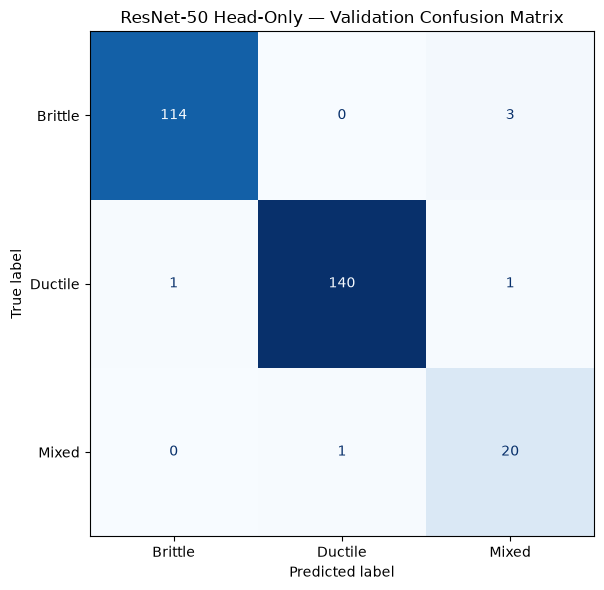

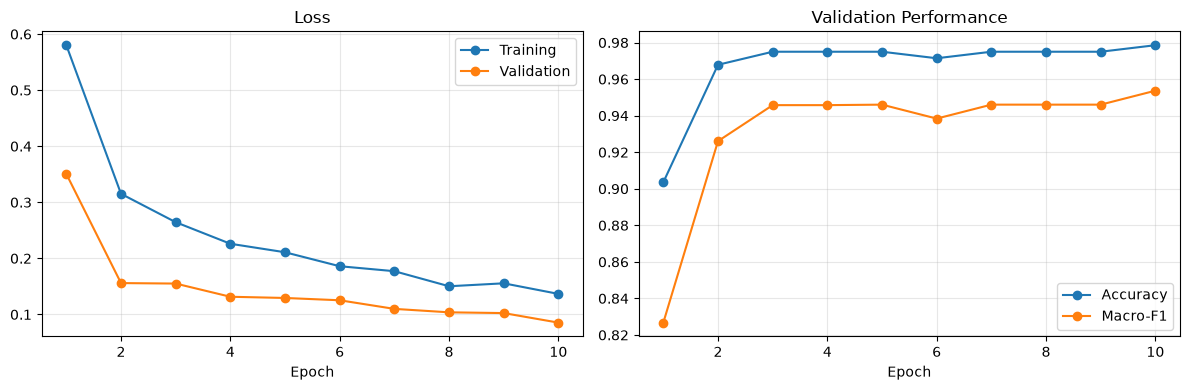


RESULTS SAVED
Validation metrics: validation_metrics.json
Predictions: validation_predictions.csv
Confusion matrix: resnet50_confusion_matrix.png
Training curves: resnet50_training_curves.png


In [6]:

import json
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# 1. EVALUATE BEST CHECKPOINT
# =====================================================

model.eval()

y_true = []
y_pred = []

with torch.inference_mode():

    for batch_images, batch_labels in val_loader:

        outputs = model(batch_images.to(DEVICE))
        predictions = outputs.argmax(dim=1)

        y_true.extend(batch_labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

assert len(y_true) == 280
assert y_true == [
    class_to_idx[r["label"]] for r in val_records
]

# =====================================================
# 2. CLASSIFICATION METRICS
# =====================================================

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

assert abs(macro_f1 - best_f1) < 1e-5

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

print("RESNET-50 VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy: {accuracy:.4%}")
print(f"Macro-F1: {macro_f1:.4f}")
print(f"Correct: {sum(a == b for a,b in zip(y_true,y_pred))}/280")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASSES,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(cm)

# =====================================================
# 3. PREDICTION-LEVEL AUDIT
# =====================================================

audit_rows = []

for record, actual, predicted in zip(
    val_records, y_true, y_pred
):
    audit_rows.append({
        "filename": record["filename"],
        "group": record["group"],
        "actual": CLASSES[actual],
        "predicted": CLASSES[predicted],
        "correct": actual == predicted
    })

audit = pd.DataFrame(audit_rows)
errors = audit[~audit["correct"]].copy()

print("\nMISCLASSIFIED IMAGES")
print("=" * 60)

if errors.empty:
    print("No misclassifications")
else:
    print(errors.to_string(index=False))

# =====================================================
# 4. CONFUSION MATRIX PLOT
# =====================================================

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "ResNet-50 Head-Only — Validation Confusion Matrix"
)

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "resnet50_confusion_matrix.png",
    dpi=200
)
plt.show()

# =====================================================
# 5. TRAINING HISTORY PLOT
# =====================================================

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs, history["train_loss"],
    marker="o", label="Training"
)
axes[0].plot(
    epochs, history["val_loss"],
    marker="o", label="Validation"
)
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs, history["val_accuracy"],
    marker="o", label="Accuracy"
)
axes[1].plot(
    epochs, history["val_macro_f1"],
    marker="o", label="Macro-F1"
)
axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "resnet50_training_curves.png",
    dpi=200
)
plt.show()

# =====================================================
# 6. SAVE RESULTS
# =====================================================

audit.to_csv(
    RESULTS_DIR / "validation_predictions.csv",
    index=False
)

results = {
    "model": "resnet50",
    "training": "head_only",
    "best_epoch": best_epoch,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "confusion_matrix": cm.tolist(),
    "classification_report": report,
    "training_time_seconds": total_time,
    "history": history
}

with open(
    RESULTS_DIR / "validation_metrics.json",
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nRESULTS SAVED")
print("=" * 60)
print("Validation metrics: validation_metrics.json")
print("Predictions: validation_predictions.csv")
print("Confusion matrix: resnet50_confusion_matrix.png")
print("Training curves: resnet50_training_curves.png")
